# Phân cụm khách hàng sàn thương mại điện tử

Bài thực nghiệm giữa kỳ môn Phân tích và Khai phá dữ liệu.

- Mã sinh viên: 24022391 (a = 1, b = 4, c = 3)
- Số bản ghi: N = 220; số thuộc tính đầu vào: 12
- Số bản ghi ngoại lai chủ động tạo: tối thiểu 11

Notebook được chia theo các câu a–e và cần chạy tuần tự từ cell đầu tiên. Bộ sinh ngẫu nhiên được khởi tạo một lần với `np.random.default_rng(42)`, nên chạy lại toàn bộ notebook sẽ cho cùng dữ liệu.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
STUDENT_ID = "24022391"
N_CUSTOMERS = 220
N_INPUT_FEATURES = 12
MIN_OUTLIER_IDS = 11

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
METADATA_DIR = PROJECT_DIR / "metadata"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"
for directory in [DATA_DIR, METADATA_DIR, FIGURE_DIR, RESULT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
print("Project directory:", PROJECT_DIR)

Project directory: T:\Datamining-\customer_segmentation


## Câu a — Thiết kế và sinh dữ liệu

### a.1. Thiết kế thuộc tính

Mỗi bản ghi là một khách hàng, kèm `customer_id` dùng để định danh và đối chiếu giữa các phiên bản dữ liệu. `customer_id` không phải thuộc tính đầu vào của thuật toán. Đơn vị tiền tệ là **nghìn đồng**.

| Thuộc tính | Ý nghĩa | Kiểu | Lý do lựa chọn |
|---|---|---|---|
| `tenure_months` | Thời gian tham gia sàn (tháng) | int | Phân biệt khách lâu năm với khách mới |
| `recency_days` | Số ngày kể từ lần mua gần nhất | int | Thành phần R trong mô hình RFM, phản ánh mức độ còn hoạt động |
| `orders_6m` | Số đơn trong 6 tháng gần nhất | int | Thành phần F (tần suất mua) |
| `total_spend_6m` | Tổng chi tiêu 6 tháng | float | Thành phần M (giá trị tiền tệ) |
| `avg_order_value` | Giá trị đơn trung bình | float | Tách khách mua ít nhưng giá trị cao với khách mua nhiều đơn nhỏ |
| `sessions_30d` | Số phiên truy cập trong 30 ngày | int | Mức độ tương tác, không đồng nghĩa với mua hàng |
| `discount_usage_rate` | Tỷ lệ đơn có dùng mã giảm giá | float [0, 1] | Nhận diện mức nhạy cảm với khuyến mãi |
| `return_rate` | Tỷ lệ đơn bị hoàn trả | float [0, 1] | Chất lượng giao dịch, rủi ro vận hành |
| `category_diversity` | Số danh mục sản phẩm đã mua (1–8) | int | Độ rộng nhu cầu mua sắm |
| `cart_abandonment_rate` | Tỷ lệ giỏ hàng bị bỏ dở | float [0, 1] | Phân biệt khách chỉ xem với khách chuyển đổi thành đơn |
| `favorite_category` | Danh mục mua nhiều nhất | category (8 mức) | Đặc điểm sở thích, hỗ trợ diễn giải cụm |
| `preferred_device` | Thiết bị mua sắm chủ yếu | category (3 mức) | Hành vi kênh mua hàng |

In [2]:
NUMERIC_FEATURES = [
    "tenure_months", "recency_days", "orders_6m", "total_spend_6m",
    "avg_order_value", "sessions_30d", "discount_usage_rate", "return_rate",
    "category_diversity", "cart_abandonment_rate",
]
CATEGORICAL_FEATURES = ["favorite_category", "preferred_device"]
INPUT_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
COUNT_FEATURES = ["tenure_months", "recency_days", "orders_6m", "sessions_30d", "category_diversity"]
RATE_FEATURES = ["discount_usage_rate", "return_rate", "cart_abandonment_rate"]

CATEGORIES = [
    "Fashion", "Electronics", "Home & Living", "Beauty & Health",
    "Groceries", "Sports & Outdoor", "Books & Stationery", "Mother & Baby",
]
DEVICES = ["Mobile App", "Mobile Web", "Desktop"]

assert len(INPUT_FEATURES) == N_INPUT_FEATURES

### a.2. Cơ chế sinh dữ liệu

Dữ liệu được sinh từ bốn nhóm hành vi tiềm ẩn. Mỗi nhóm có bộ tham số phân phối riêng, nhưng các phân phối được chọn đủ rộng để các nhóm giao thoa nhau:

| Nhóm | Số khách | Đặc trưng chính |
|---|---|---|
| Loyal | 55 | Nhiều đơn, giá trị đơn cao, recency thấp, ít bỏ giỏ |
| Discount Seeker | 60 | Tỷ lệ dùng giảm giá cao, giá trị đơn thấp hơn, chi tiêu vừa phải |
| Browser | 55 | Truy cập nhiều, ít đơn, tỷ lệ bỏ giỏ cao |
| Inactive | 50 | Ít truy cập, ít đơn, recency cao |

Phân phối sử dụng:

- `tenure_months`: Normal, làm tròn và cắt trong [1, 120].
- `orders_6m` = 1 + Poisson(λ theo nhóm).
- `avg_order_value`: Lognormal, vì giá trị tiền tệ thường lệch phải.
- `sessions_30d`: Poisson với cường độ nhân thêm hệ số Gamma(3, 1/3), tức phân phối Negative Binomial. Hệ số này tạo khác biệt giữa các cá nhân trong cùng nhóm, làm các nhóm chồng lấn hơn.
- `recency_days`: Exponential với thang đo 180 / (orders_6m + 1) × hệ số nhóm. Khách mua nhiều thì lần mua gần nhất có xu hướng gần hơn.
- Các tỷ lệ: Beta, nên luôn nằm trong [0, 1].
- `category_diversity` = 1 + Poisson, cắt tối đa 8 (số danh mục của sàn).
- Hai biến phân loại: phân phối categorical với xác suất khác nhau theo nhóm.

Quy ước đơn giản hóa để dữ liệu nhất quán logic:

1. Tập khách hàng chỉ gồm khách có ít nhất 1 đơn trong 6 tháng, nên `orders_6m ≥ 1` và `recency_days ≤ 180`. Nhờ vậy `avg_order_value` luôn xác định.
2. `total_spend_6m = orders_6m × avg_order_value` (định nghĩa của giá trị đơn trung bình).
3. `recency_days ≤ 30 × tenure_months`: không thể mua trước khi tham gia sàn.
4. Nếu `recency_days ≤ 30` thì `sessions_30d ≥ 1`: có mua trong 30 ngày thì phải có ít nhất một phiên truy cập.
5. Các tỷ lệ được sinh như xu hướng hành vi liên tục, không suy ra từ số đơn rời rạc. Với khách chỉ có 1–2 đơn, tỷ lệ thực tế sẽ thô hơn.

Nhãn `true_segment` chỉ được lưu trong metadata để kiểm chứng giả lập. Nhãn này không nằm trong dữ liệu đầu vào và không được dùng ở bước tiền xử lý hay chọn mô hình.

In [3]:
SEGMENT_SIZES = {"Loyal": 55, "Discount Seeker": 60, "Browser": 55, "Inactive": 50}

# Xác suất danh mục theo thứ tự CATEGORIES; xác suất thiết bị theo thứ tự DEVICES.
SEGMENT_PARAMS = {
    "Loyal": dict(
        tenure=(36, 14), extra_orders=11.0, aov_median=650, aov_sigma=0.35,
        recency_factor=0.8, session_rate=16, discount_beta=(2, 6), return_beta=(1.5, 18),
        extra_categories=3.5, cart_beta=(2, 7),
        category_probs=[0.15, 0.20, 0.18, 0.12, 0.15, 0.08, 0.06, 0.06],
        device_probs=[0.60, 0.15, 0.25],
    ),
    "Discount Seeker": dict(
        tenure=(22, 12), extra_orders=6.0, aov_median=380, aov_sigma=0.35,
        recency_factor=1.0, session_rate=14, discount_beta=(7, 3), return_beta=(2, 12),
        extra_categories=2.5, cart_beta=(4, 5),
        category_probs=[0.25, 0.08, 0.12, 0.20, 0.18, 0.07, 0.04, 0.06],
        device_probs=[0.55, 0.30, 0.15],
    ),
    "Browser": dict(
        tenure=(15, 10), extra_orders=1.5, aov_median=450, aov_sigma=0.45,
        recency_factor=1.2, session_rate=24, discount_beta=(3, 5), return_beta=(2, 10),
        extra_categories=1.2, cart_beta=(7, 3),
        category_probs=[0.22, 0.25, 0.10, 0.12, 0.05, 0.12, 0.09, 0.05],
        device_probs=[0.35, 0.35, 0.30],
    ),
    "Inactive": dict(
        tenure=(24, 16), extra_orders=0.4, aov_median=400, aov_sigma=0.50,
        recency_factor=1.4, session_rate=4, discount_beta=(2, 4), return_beta=(1.5, 12),
        extra_categories=0.4, cart_beta=(4, 4),
        category_probs=[0.18, 0.14, 0.14, 0.12, 0.12, 0.10, 0.10, 0.10],
        device_probs=[0.30, 0.40, 0.30],
    ),
}

assert sum(SEGMENT_SIZES.values()) == N_CUSTOMERS
for params in SEGMENT_PARAMS.values():
    assert np.isclose(sum(params["category_probs"]), 1) and np.isclose(sum(params["device_probs"]), 1)

In [4]:
def generate_segment(size, params, rng):
    # Sinh khách hàng của một nhóm tiềm ẩn theo bộ tham số của nhóm đó.
    tenure = np.clip(np.round(rng.normal(*params["tenure"], size)), 1, 120).astype(int)
    orders = 1 + rng.poisson(params["extra_orders"], size)
    avg_order_value = rng.lognormal(np.log(params["aov_median"]), params["aov_sigma"], size).round(2)
    total_spend = (orders * avg_order_value).round(2)

    recency_scale = 180 / (orders + 1) * params["recency_factor"]
    recency = np.clip(np.round(rng.exponential(recency_scale)), 0, 180).astype(int)
    recency = np.minimum(recency, 30 * tenure)

    # Gamma-Poisson: mỗi khách có cường độ truy cập riêng quanh mức trung bình của nhóm.
    session_intensity = params["session_rate"] * rng.gamma(3.0, 1 / 3.0, size)
    sessions = rng.poisson(session_intensity)
    sessions = np.where(recency <= 30, np.maximum(sessions, 1), sessions)

    return pd.DataFrame({
        "tenure_months": tenure,
        "recency_days": recency,
        "orders_6m": orders,
        "total_spend_6m": total_spend,
        "avg_order_value": avg_order_value,
        "sessions_30d": sessions,
        "discount_usage_rate": rng.beta(*params["discount_beta"], size).round(3),
        "return_rate": rng.beta(*params["return_beta"], size).round(3),
        "category_diversity": np.minimum(1 + rng.poisson(params["extra_categories"], size), len(CATEGORIES)),
        "cart_abandonment_rate": rng.beta(*params["cart_beta"], size).round(3),
        "favorite_category": rng.choice(CATEGORIES, size, p=params["category_probs"]),
        "preferred_device": rng.choice(DEVICES, size, p=params["device_probs"]),
    })


def generate_clean_customers(rng):
    parts = []
    for segment, size in SEGMENT_SIZES.items():
        part = generate_segment(size, SEGMENT_PARAMS[segment], rng)
        part.insert(0, "true_segment", segment)
        parts.append(part)
    customers = pd.concat(parts, ignore_index=True)
    # Xáo trộn để thứ tự bản ghi không lộ nhóm tiềm ẩn.
    customers = customers.iloc[rng.permutation(len(customers))].reset_index(drop=True)
    customers.insert(0, "customer_id", [f"C{i:04d}" for i in range(1, len(customers) + 1)])
    return customers

In [5]:
rng = np.random.default_rng(SEED)

simulated = generate_clean_customers(rng)
customers_original = simulated[["customer_id"] + INPUT_FEATURES].copy()
segment_labels = simulated[["customer_id", "true_segment"]].copy()

print(customers_original.shape)
customers_original.head()

(220, 13)


,customer_id,tenure_months,recency_days,orders_6m,total_spend_6m,avg_order_value,sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate,favorite_category,preferred_device
0,C0001,1,30,2,895.20,447.60,18,0.789,0.147,1,0.317,Home & Living,Mobile App
1,C0002,39,3,11,5814.60,528.60,6,0.333,0.017,4,0.129,Electronics,Mobile App
2,C0003,40,122,1,388.01,388.01,40,0.184,0.240,1,0.834,Sports & Outdoor,Desktop
3,C0004,45,24,18,9305.82,516.99,15,0.188,0.002,4,0.308,Electronics,Mobile App
4,C0005,53,2,14,6774.32,483.88,12,0.385,0.026,3,0.299,Beauty & Health,Mobile App


In [6]:
def check_clean_data(df):
    # Kiểm tra các ràng buộc logic của dữ liệu sạch.
    assert len(df) == N_CUSTOMERS
    assert df["customer_id"].is_unique
    assert [c for c in df.columns if c != "customer_id"] == INPUT_FEATURES
    assert not df[INPUT_FEATURES].isna().any().any()
    for col in COUNT_FEATURES:
        assert pd.api.types.is_integer_dtype(df[col]) and (df[col] >= 0).all(), col
    for col in RATE_FEATURES:
        assert df[col].between(0, 1).all(), col
    assert (df["orders_6m"] >= 1).all() and (df["recency_days"] <= 180).all()
    assert np.allclose(df["total_spend_6m"], df["orders_6m"] * df["avg_order_value"], atol=0.01)
    assert (df["recency_days"] <= 30 * df["tenure_months"]).all()
    assert (df.loc[df["recency_days"] <= 30, "sessions_30d"] >= 1).all()
    assert df["category_diversity"].between(1, len(CATEGORIES)).all()
    assert set(df["favorite_category"]) <= set(CATEGORIES) and set(df["preferred_device"]) <= set(DEVICES)
    print(f"Clean data OK: {len(df)} records, {len(INPUT_FEATURES)} input features")


check_clean_data(customers_original)
customers_original[NUMERIC_FEATURES].describe().T.round(2)

Clean data OK: 220 records, 12 input features


,count,mean,std,min,25%,50%,75%,max
tenure_months,220.0,24.75,14.20,1.00,14.00,24.00,36.00,66.00
recency_days,220.0,39.16,48.21,0.00,7.00,21.00,45.25,180.00
orders_6m,220.0,5.85,4.77,1.00,2.00,4.00,9.00,19.00
total_spend_6m,220.0,3287.77,3610.79,95.26,779.96,1935.90,4541.03,18834.70
avg_order_value,220.0,512.62,260.90,95.26,359.12,437.36,614.47,1789.31
sessions_30d,220.0,14.95,12.88,0.00,5.00,12.00,20.25,86.00
discount_usage_rate,220.0,0.43,0.24,0.01,0.24,0.41,0.60,0.97
return_rate,220.0,0.12,0.09,0.00,0.05,0.10,0.17,0.45
category_diversity,220.0,2.73,1.77,1.00,1.00,2.00,4.00,8.00
cart_abandonment_rate,220.0,0.48,0.22,0.03,0.31,0.46,0.66,0.98


**Kiểm chứng giả lập (dùng nhãn tiềm ẩn).** Bảng trung bình theo nhóm và biểu đồ hộp dưới đây chỉ dùng để xác nhận cơ chế sinh dữ liệu hoạt động đúng thiết kế, tức các nhóm khác nhau theo hướng dự kiến nhưng vẫn chồng lấn. Kết quả này không được dùng ở các bước sau.

In [7]:
segment_view = customers_original.merge(segment_labels, on="customer_id")
segment_view.groupby("true_segment")[NUMERIC_FEATURES].mean().round(2).T

true_segment,Browser,Discount Seeker,Inactive,Loyal
tenure_months,16.20,22.67,23.38,36.84
recency_days,49.85,21.62,80.86,9.71
orders_6m,2.51,6.82,1.20,12.36
total_spend_6m,1305.70,2737.28,578.26,8333.57
avg_order_value,494.76,406.51,474.39,681.00
sessions_30d,25.45,13.02,4.00,16.49
discount_usage_rate,0.40,0.71,0.33,0.25
return_rate,0.17,0.14,0.11,0.07
category_diversity,2.04,3.12,1.28,4.31
cart_abandonment_rate,0.70,0.47,0.49,0.27


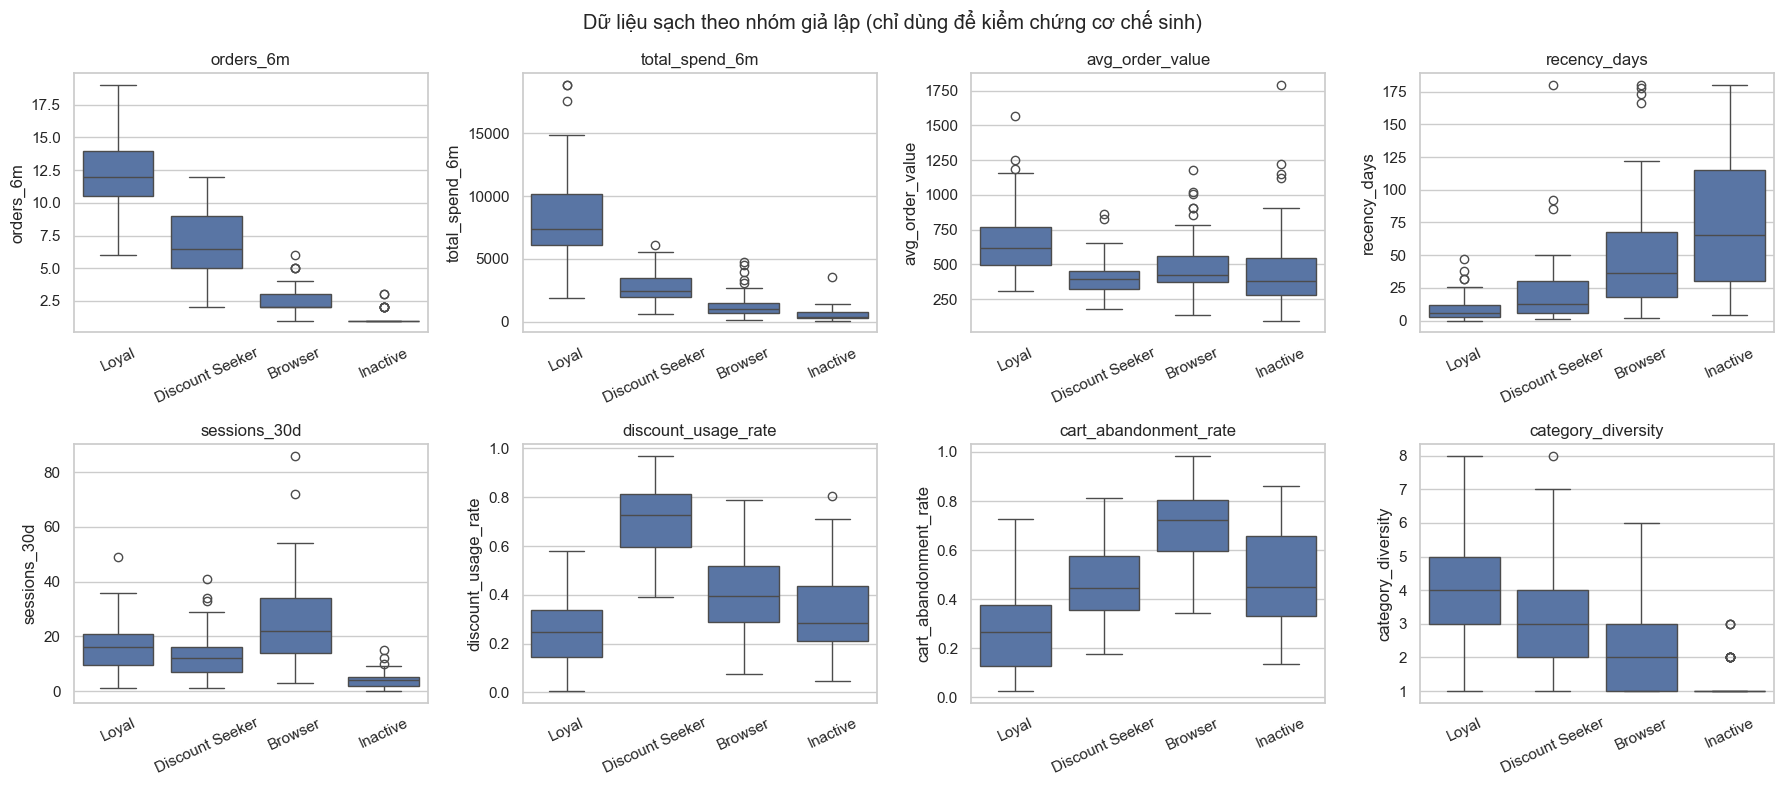

In [8]:
plot_features = [
    "orders_6m", "total_spend_6m", "avg_order_value", "recency_days",
    "sessions_30d", "discount_usage_rate", "cart_abandonment_rate", "category_diversity",
]
segment_order = list(SEGMENT_SIZES)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), plot_features):
    sns.boxplot(data=segment_view, x="true_segment", y=col, order=segment_order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Dữ liệu sạch theo nhóm giả lập (chỉ dùng để kiểm chứng cơ chế sinh)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "a_clean_features_by_segment.png", dpi=150)
plt.show()

Để đánh giá định lượng mức giao thoa, tính silhouette của **nhãn giả lập** trên 10 thuộc tính số đã chuẩn hóa. Giá trị gần 1 cho thấy các nhóm tách biệt rõ, tức dữ liệu quá dễ phân cụm. Giá trị gần 0 cho thấy các nhóm chồng lấn mạnh. Chỉ số này chỉ dùng để mô tả dữ liệu giả lập.

In [9]:
scaled_clean_numeric = StandardScaler().fit_transform(customers_original[NUMERIC_FEATURES])
true_label_silhouette = silhouette_score(scaled_clean_numeric, segment_view["true_segment"])
print(f"Silhouette of simulated segments (clean, standardized numeric features): {true_label_silhouette:.3f}")

Silhouette of simulated segments (clean, standardized numeric features): 0.177


**Nhận xét.** Trung bình theo nhóm thay đổi theo đúng hướng đã thiết kế:

- Loyal có số đơn (12.36), chi tiêu (8333.57) và giá trị đơn (681.00) cao nhất, recency thấp nhất (9.71 ngày).
- Discount Seeker có `discount_usage_rate` cao nhất (0.71).
- Browser có số phiên cao nhất (25.45) nhưng chỉ 2.51 đơn, và tỷ lệ bỏ giỏ cao nhất (0.70).
- Inactive có số phiên (4.00) và số đơn (1.20) thấp nhất, recency cao nhất (80.86 ngày).

Biểu đồ hộp cho thấy nhiều biến chồng lấn đáng kể giữa các nhóm, đặc biệt `avg_order_value`, `return_rate` và `sessions_30d` giữa Loyal và Discount Seeker. Silhouette của nhãn giả lập là 0.177, tức các nhóm có cấu trúc nhưng không tách biệt rõ. Mức này phù hợp yêu cầu tránh dữ liệu quá dễ phân cụm.

### a.3. Đưa vào các vấn đề chất lượng dữ liệu

Thứ tự can thiệp trên bản sao `customers_corrupted`:

1. **Chọn bản ghi ngoại lai trước** (12 `customer_id`), sau đó loại các bản ghi này khỏi tập ứng viên của nhiễu và giá trị thiếu. Mỗi bản ghi ngoại lai vì thế chỉ chịu đúng một loại can thiệp, nên việc đối chiếu và đánh giá khả năng phát hiện không bị lẫn.
2. **Thêm nhiễu Gaussian** vào `total_spend_6m` và `sessions_30d`.
3. **Áp dụng ngoại lai.**
4. **Tạo giá trị thiếu** cho `avg_order_value` (MCAR) và `cart_abandonment_rate` (MAR).

Mọi can thiệp được ghi vào `simulation_metadata`.

#### Nhiễu Gaussian

Độ lớn nhiễu được chọn theo thang đo và dạng phân phối của từng biến:

- `total_spend_6m` lệch phải mạnh (từ vài trăm đến hàng chục nghìn). Một độ lệch chuẩn tuyệt đối chung sẽ làm khách chi tiêu thấp bị biến dạng rất mạnh, thậm chí ra giá trị âm. Vì vậy dùng nhiễu Gaussian **tương đối**: `x' = x · (1 + ε)`, với ε ~ N(0, 0.15²). Độ lệch chuẩn tuyệt đối của nhiễu tỷ lệ với giá trị gốc, tương ứng sai số ghi nhận hoặc quy đổi doanh thu.
- `sessions_30d` có thang đo hẹp: dùng nhiễu cộng `x' = x + ε`, với ε ~ N(0, (0.25 · σ_sessions)²), trong đó σ_sessions là độ lệch chuẩn của biến trên dữ liệu sạch. Kết quả làm tròn về số nguyên và cắt dưới tại 0 vì đây là biến đếm.

Mỗi biến được thêm nhiễu trên 40% số bản ghi. Các bản ghi được chọn ngẫu nhiên, độc lập giữa hai biến.

In [10]:
OUTLIER_BUSINESS_COUNT = 5
OUTLIER_ERROR_COUNT = 7
NOISE_FRACTION = 0.40
SPEND_RELATIVE_NOISE_SD = 0.15
SESSIONS_NOISE_SD_RATIO = 0.25
MISSING_AOV_RATE = 0.07    # MCAR
MISSING_CART_RATE = 0.08   # MAR theo sessions_30d


def select_outlier_ids(segment_labels, rng):
    # Ngoại lai nghiệp vụ lấy từ nhóm Loyal (khách VIP có thật); ngoại lai lỗi lấy ngẫu nhiên từ phần còn lại.
    loyal_ids = segment_labels.loc[segment_labels["true_segment"] == "Loyal", "customer_id"].to_numpy()
    business_ids = rng.choice(loyal_ids, OUTLIER_BUSINESS_COUNT, replace=False)
    remaining_ids = np.setdiff1d(segment_labels["customer_id"].to_numpy(), business_ids)
    error_ids = rng.choice(remaining_ids, OUTLIER_ERROR_COUNT, replace=False)
    return list(business_ids), list(error_ids)


def add_gaussian_noise(df, eligible_ids, rng):
    # Trả về bản dữ liệu đã thêm nhiễu và bảng log nhiễu theo từng bản ghi.
    noisy = df.copy()
    n_noisy = round(NOISE_FRACTION * len(df))
    logs = []

    spend_ids = rng.choice(eligible_ids, n_noisy, replace=False)
    mask = noisy["customer_id"].isin(spend_ids)
    before = noisy.loc[mask, "total_spend_6m"]
    epsilon = rng.normal(0, SPEND_RELATIVE_NOISE_SD, mask.sum())
    noisy.loc[mask, "total_spend_6m"] = np.maximum(before * (1 + epsilon), 0).round(2)
    logs.append(pd.DataFrame({"customer_id": noisy.loc[mask, "customer_id"], "column": "total_spend_6m",
                              "before": before, "after": noisy.loc[mask, "total_spend_6m"]}))

    sessions_sd = SESSIONS_NOISE_SD_RATIO * df["sessions_30d"].std()
    session_ids = rng.choice(eligible_ids, n_noisy, replace=False)
    mask = noisy["customer_id"].isin(session_ids)
    before = noisy.loc[mask, "sessions_30d"]
    noisy_values = np.maximum(np.round(before + rng.normal(0, sessions_sd, mask.sum())), 0)
    noisy.loc[mask, "sessions_30d"] = noisy_values.astype(int)
    logs.append(pd.DataFrame({"customer_id": noisy.loc[mask, "customer_id"], "column": "sessions_30d",
                              "before": before, "after": noisy.loc[mask, "sessions_30d"]}))

    noise_log = pd.concat(logs, ignore_index=True)
    noise_log["delta"] = noise_log["after"] - noise_log["before"]
    noise_params = {"total_spend_6m": f"relative N(0, {SPEND_RELATIVE_NOISE_SD}^2)",
                    "sessions_30d": f"additive N(0, {sessions_sd:.3f}^2)"}
    return noisy, noise_log, noise_params

#### Ngoại lai

Chọn 12 `customer_id` khác nhau (nhiều hơn mức tối thiểu 11):

- **5 ngoại lai hợp lệ về nghiệp vụ**, lấy từ nhóm Loyal. Giá trị vẫn tuân thủ các ràng buộc logic, ví dụ `total_spend_6m = orders_6m × avg_order_value` vẫn đúng:
  - 3 khách VIP chi tiêu lớn: `avg_order_value` nhân 4–6 lần.
  - 2 khách mua rất thường xuyên: 60–80 đơn trong 6 tháng, 60–90 phiên truy cập, recency 0–2 ngày.
- **7 ngoại lai do lỗi dữ liệu**, mỗi bản ghi vi phạm một ràng buộc:
  - 2 bản ghi lỗi đơn vị: `total_spend_6m` × 100.
  - 1 bản ghi lỗi tracking: `sessions_30d` = 999.
  - 1 bản ghi tỷ lệ vượt khoảng hợp lệ: `return_rate` = 1.85.
  - 1 bản ghi tỷ lệ âm: `discount_usage_rate` = −0.40.
  - 1 bản ghi giá trị âm: `tenure_months` = −12.
  - 1 bản ghi giá trị âm: `recency_days` = −15.

In [11]:
ERROR_RULES = [
    ("spend_unit_x100", "total_spend_6m"),
    ("spend_unit_x100", "total_spend_6m"),
    ("sessions_tracking_999", "sessions_30d"),
    ("return_rate_above_1", "return_rate"),
    ("discount_rate_negative", "discount_usage_rate"),
    ("tenure_negative", "tenure_months"),
    ("recency_negative", "recency_days"),
]


def apply_business_outliers(df, business_ids, rng):
    records = []
    for i, cid in enumerate(business_ids):
        idx = df.index[df["customer_id"] == cid][0]
        if i < 3:
            rule = "vip_high_order_value"
            df.loc[idx, "avg_order_value"] = round(df.loc[idx, "avg_order_value"] * rng.uniform(4, 6), 2)
            columns = ["avg_order_value", "total_spend_6m"]
        else:
            rule = "very_high_frequency"
            df.loc[idx, "orders_6m"] = rng.integers(60, 81)
            df.loc[idx, "sessions_30d"] = rng.integers(60, 91)
            df.loc[idx, "recency_days"] = rng.integers(0, 3)
            columns = ["orders_6m", "sessions_30d", "recency_days", "total_spend_6m"]
        # Giữ đúng định nghĩa tổng chi tiêu để ngoại lai vẫn hợp lệ về nghiệp vụ.
        df.loc[idx, "total_spend_6m"] = round(df.loc[idx, "orders_6m"] * df.loc[idx, "avg_order_value"], 2)
        records.append({"customer_id": cid, "outlier_type": "business_valid",
                        "outlier_rule": rule, "outlier_columns": ";".join(columns)})
    return records


def apply_error_outliers(df, error_ids):
    records = []
    for cid, (rule, column) in zip(error_ids, ERROR_RULES):
        idx = df.index[df["customer_id"] == cid][0]
        if rule == "spend_unit_x100":
            df.loc[idx, column] = round(df.loc[idx, column] * 100, 2)
        else:
            df.loc[idx, column] = {"sessions_tracking_999": 999, "return_rate_above_1": 1.85,
                                   "discount_rate_negative": -0.40, "tenure_negative": -12,
                                   "recency_negative": -15}[rule]
        records.append({"customer_id": cid, "outlier_type": "data_error",
                        "outlier_rule": rule, "outlier_columns": column})
    return records

#### Giá trị thiếu

- `avg_order_value`, **MCAR**: chọn ngẫu nhiên đều 7% số bản ghi (15 bản ghi). Việc thiếu không phụ thuộc vào bất kỳ giá trị nào.
- `cart_abandonment_rate`, **MAR**: 8% số bản ghi (18 bản ghi). Xác suất thiếu tỷ lệ với exp(−sessions_30d / 10), trong đó `sessions_30d` là giá trị quan sát được sau nhiễu. Giả định: khách ít truy cập có ít sự kiện giỏ hàng nên tỷ lệ bỏ giỏ khó được ghi nhận. Cơ chế thiếu phụ thuộc vào một biến quan sát được, không phụ thuộc vào chính giá trị bị thiếu hay nhãn nhóm.

In [12]:
def add_missing_values(df, eligible_ids, rng):
    eligible_mask = df["customer_id"].isin(eligible_ids)
    eligible = df.loc[eligible_mask]

    n_aov = round(MISSING_AOV_RATE * len(df))
    aov_ids = rng.choice(eligible["customer_id"].to_numpy(), n_aov, replace=False)

    n_cart = round(MISSING_CART_RATE * len(df))
    weights = np.exp(-eligible["sessions_30d"].to_numpy() / 10)
    cart_ids = rng.choice(eligible["customer_id"].to_numpy(), n_cart, replace=False, p=weights / weights.sum())

    df.loc[df["customer_id"].isin(aov_ids), "avg_order_value"] = np.nan
    df.loc[df["customer_id"].isin(cart_ids), "cart_abandonment_rate"] = np.nan
    return set(aov_ids), set(cart_ids)

In [13]:
business_ids, error_ids = select_outlier_ids(segment_labels, rng)
outlier_ids = business_ids + error_ids
non_outlier_ids = np.setdiff1d(customers_original["customer_id"].to_numpy(), outlier_ids)

customers_corrupted, noise_log, noise_params = add_gaussian_noise(customers_original, non_outlier_ids, rng)
outlier_records = apply_business_outliers(customers_corrupted, business_ids, rng)
outlier_records += apply_error_outliers(customers_corrupted, error_ids)
missing_aov_ids, missing_cart_ids = add_missing_values(customers_corrupted, non_outlier_ids, rng)

print("Noise parameters:", noise_params)
print("Outlier ids:", outlier_ids)

Noise parameters: {'total_spend_6m': 'relative N(0, 0.15^2)', 'sessions_30d': 'additive N(0, 3.219^2)'}
Outlier ids: ['C0197', 'C0129', 'C0118', 'C0077', 'C0133', 'C0143', 'C0146', 'C0137', 'C0127', 'C0013', 'C0192', 'C0131']


In [14]:
def build_simulation_metadata():
    meta = segment_labels.copy()
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        deltas = noise_log.loc[noise_log["column"] == column].set_index("customer_id")["delta"]
        meta[flag] = meta["customer_id"].isin(deltas.index)
        meta[f"{flag}_delta"] = meta["customer_id"].map(deltas).fillna(0.0)

    outlier_table = pd.DataFrame(outlier_records)
    meta = meta.merge(outlier_table, on="customer_id", how="left")
    meta["is_outlier"] = meta["outlier_type"].notna()
    meta[["outlier_type", "outlier_rule", "outlier_columns"]] = (
        meta[["outlier_type", "outlier_rule", "outlier_columns"]].fillna("none"))

    meta["missing_avg_order_value"] = meta["customer_id"].isin(missing_aov_ids)
    meta["missing_cart_abandonment_rate"] = meta["customer_id"].isin(missing_cart_ids)

    def error_types(row):
        types = []
        if row["missing_avg_order_value"] or row["missing_cart_abandonment_rate"]:
            types.append("missing")
        if row["noise_total_spend"] or row["noise_sessions"]:
            types.append("noise")
        if row["is_outlier"]:
            types.append(f"outlier_{row['outlier_type']}")
        return ";".join(types) if types else "clean"

    meta["error_types"] = meta.apply(error_types, axis=1)
    return meta


simulation_metadata = build_simulation_metadata()
print(simulation_metadata["error_types"].value_counts().to_string())
simulation_metadata.head()

error_types
noise                     118
clean                      59
missing;noise              20
missing                    11
outlier_data_error          7
outlier_business_valid      5


,customer_id,true_segment,noise_total_spend,noise_total_spend_delta,noise_sessions,noise_sessions_delta,outlier_type,outlier_rule,outlier_columns,is_outlier,missing_avg_order_value,missing_cart_abandonment_rate,error_types
0,C0001,Discount Seeker,False,0.00,False,0.0,none,none,none,False,True,True,missing
1,C0002,Loyal,False,0.00,False,0.0,none,none,none,False,False,False,clean
2,C0003,Browser,True,-13.75,True,0.0,none,none,none,False,False,False,noise
3,C0004,Loyal,True,-632.60,True,-1.0,none,none,none,False,False,False,noise
4,C0005,Loyal,False,0.00,True,-4.0,none,none,none,False,False,False,noise


Kiểm tra cơ chế thiếu: với MCAR, `sessions_30d` của nhóm thiếu và không thiếu `avg_order_value` không nên khác nhau có hệ thống. Với MAR, nhóm thiếu `cart_abandonment_rate` dự kiến có `sessions_30d` thấp hơn.

In [15]:
missing_mechanism_check = pd.DataFrame({
    column: customers_corrupted.groupby(customers_corrupted[column].isna())["sessions_30d"].median()
    for column in ["avg_order_value", "cart_abandonment_rate"]
}).rename(index={False: "observed", True: "missing"})
missing_mechanism_check.index.name = "median sessions_30d when value is"
missing_mechanism_check

,avg_order_value,cart_abandonment_rate
median sessions_30d when value is,,
observed,12.0,13.5
missing,11.0,4.5


**Nhận xét.**

- `avg_order_value` (MCAR): median `sessions_30d` của nhóm thiếu và nhóm quan sát được gần nhau (11 so với 12).
- `cart_abandonment_rate` (MAR): median `sessions_30d` của nhóm thiếu chỉ là 4.5, so với 13.5 ở nhóm quan sát được. Như vậy cơ chế thiếu phụ thuộc vào một biến quan sát được, đúng thiết kế.

Hệ quả cho tiền xử lý: điền `cart_abandonment_rate` bằng trung vị toàn cục có thể lệch, vì các bản ghi thiếu tập trung ở khách ít truy cập. Cần cân nhắc phương pháp điền có sử dụng biến quan sát khác.

Về phân bố can thiệp: 59 bản ghi không bị can thiệp, 118 bản ghi chỉ có nhiễu, 11 bản ghi chỉ có giá trị thiếu, 20 bản ghi có cả nhiễu lẫn giá trị thiếu, và 12 bản ghi ngoại lai.

### a.4. Mức độ thay đổi do nhiễu và đối chiếu ngoại lai

In [16]:
noise_summary = noise_log.groupby("column").agg(
    n_records=("customer_id", "nunique"),
    mean_before=("before", "mean"),
    mean_after=("after", "mean"),
    mean_abs_delta=("delta", lambda d: d.abs().mean()),
    max_abs_delta=("delta", lambda d: d.abs().max()),
)
noise_summary["mean_abs_relative_change"] = noise_log.assign(
    rel=lambda t: (t["delta"] / t["before"].where(t["before"] != 0)).abs()
).groupby("column")["rel"].mean()
noise_summary["corr_before_after"] = noise_log.groupby("column")[["before", "after"]].apply(
    lambda t: t["before"].corr(t["after"]))
noise_summary["clean_std"] = [customers_original[c].std() for c in noise_summary.index]
noise_summary.round(3)

,n_records,mean_before,mean_after,mean_abs_delta,max_abs_delta,mean_abs_relative_change,corr_before_after,clean_std
column,,,,,,,,
sessions_30d,88,16.295,16.614,2.432,7.0,0.352,0.974,12.875
total_spend_6m,88,3366.682,3217.773,388.625,4528.8,0.100,0.982,3610.793


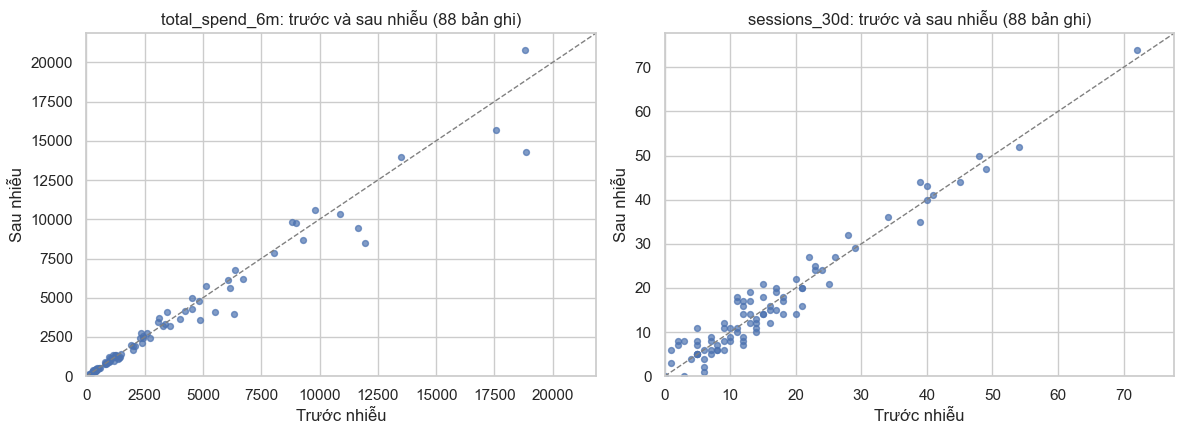

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, ["total_spend_6m", "sessions_30d"]):
    subset = noise_log[noise_log["column"] == column]
    ax.scatter(subset["before"], subset["after"], s=18, alpha=0.7)
    lim = [0, max(subset["before"].max(), subset["after"].max()) * 1.05]
    ax.plot(lim, lim, color="grey", linestyle="--", linewidth=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_title(f"{column}: trước và sau nhiễu ({len(subset)} bản ghi)")
    ax.set_xlabel("Trước nhiễu")
    ax.set_ylabel("Sau nhiễu")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "a_noise_before_after.png", dpi=150)
plt.show()

**Nhận xét.** Mỗi biến có 88 bản ghi bị tác động (40%):

- `total_spend_6m`: thay đổi tương đối trung bình khoảng 10%, tương quan trước/sau là 0.982. Độ lệch tuyệt đối lớn nhất (khoảng 4529) rơi vào khách chi tiêu cao, đúng với tính chất nhiễu tương đối.
- `sessions_30d`: thay đổi tuyệt đối trung bình 2.43 phiên. Thay đổi tương đối trung bình lên tới 35% vì nhiều khách chỉ có vài phiên. Có 74/88 bản ghi thực sự đổi giá trị; số còn lại có nhiễu bị làm tròn về 0 hoặc bị cắt tại 0.

Nhiễu làm giảm tính nhất quán `total_spend_6m = orders_6m × avg_order_value` ở các bản ghi bị tác động, nhưng chưa tạo ra giá trị cực đoan.

In [18]:
def outlier_comparison_table():
    rows = []
    for record in outlier_records:
        cid = record["customer_id"]
        for column in record["outlier_columns"].split(";"):
            rows.append({
                "customer_id": cid,
                "outlier_type": record["outlier_type"],
                "outlier_rule": record["outlier_rule"],
                "column": column,
                "original_value": customers_original.loc[customers_original["customer_id"] == cid, column].iloc[0],
                "corrupted_value": customers_corrupted.loc[customers_corrupted["customer_id"] == cid, column].iloc[0],
            })
    return pd.DataFrame(rows)


outlier_comparison = outlier_comparison_table()
outlier_comparison

,customer_id,outlier_type,outlier_rule,column,original_value,corrupted_value
0,C0197,business_valid,vip_high_order_value,avg_order_value,482.190,2803.41
1,C0197,business_valid,vip_high_order_value,total_spend_6m,6750.660,39247.74
2,C0129,business_valid,vip_high_order_value,avg_order_value,601.020,3027.50
3,C0129,business_valid,vip_high_order_value,total_spend_6m,7212.240,36330.00
4,C0118,business_valid,vip_high_order_value,avg_order_value,1084.070,6064.05
5,C0118,business_valid,vip_high_order_value,total_spend_6m,10840.700,60640.50
6,C0077,business_valid,very_high_frequency,orders_6m,12.000,63.00
7,C0077,business_valid,very_high_frequency,sessions_30d,14.000,85.00
8,C0077,business_valid,very_high_frequency,recency_days,5.000,2.00
9,C0077,business_valid,very_high_frequency,total_spend_6m,8778.240,46085.76


**Nhận xét.** 12 `customer_id` đã được can thiệp đúng như thiết kế.

- **Ngoại lai nghiệp vụ** có `total_spend_6m` từ khoảng 36 nghìn đến 80 nghìn, trong khi giá trị lớn nhất ở dữ liệu sạch là 18834.70. Chúng vẫn thỏa mọi ràng buộc logic, nên chỉ phương pháp thống kê (IQR, z-score, …) mới phát hiện được.
- **Ngoại lai lỗi** chia làm hai loại:
  - 4 bản ghi vi phạm miền giá trị (âm hoặc tỷ lệ > 1): có thể phát hiện bằng kiểm tra quy tắc nghiệp vụ.
  - 3 bản ghi có giá trị cực lớn (`total_spend_6m` × 100, `sessions_30d` = 999): vẫn hợp lệ về miền nhưng lệch rất xa phân phối.

Phần lớn ngoại lai lỗi chỉ lệch ở một cột, trong khi các cột còn lại bình thường. Do đó nếu chỉ kiểm tra từng biến riêng lẻ theo một phương pháp thống kê, một số bản ghi có thể không bị phát hiện. Khả năng phát hiện sẽ được đánh giá định lượng ở câu b.

### a.5. Kiểm tra tự động và lưu dữ liệu

In [19]:
def run_simulation_checks(original, corrupted, metadata):
    results = {}

    results["original_records"] = len(original)
    results["corrupted_records"] = len(corrupted)
    results["input_features"] = len([c for c in original.columns if c != "customer_id"])
    assert results["original_records"] == N_CUSTOMERS and results["corrupted_records"] == N_CUSTOMERS
    assert results["input_features"] == N_INPUT_FEATURES
    assert list(original.columns) == list(corrupted.columns)

    # Đối chiếu bằng customer_id: cùng tập id, không trùng lặp, cùng thứ tự.
    assert original["customer_id"].is_unique and corrupted["customer_id"].is_unique
    assert set(original["customer_id"]) == set(corrupted["customer_id"]) == set(metadata["customer_id"])
    assert (original["customer_id"].to_numpy() == corrupted["customer_id"].to_numpy()).all()

    assert original[INPUT_FEATURES].notna().all().all()
    missing_rate = corrupted[INPUT_FEATURES].isna().mean()
    missing_columns = missing_rate[missing_rate > 0]
    assert len(missing_columns) >= 2
    assert missing_columns.between(0.05, 0.10).all()
    results.update({f"missing_rate_{c}": round(r, 4) for c, r in missing_columns.items()})

    original_idx = original.set_index("customer_id")
    corrupted_idx = corrupted.set_index("customer_id")
    noisy_columns = []
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        noise_ids = metadata.loc[metadata[flag], "customer_id"]
        assert pd.api.types.is_numeric_dtype(corrupted[column])
        changed = (corrupted_idx.loc[noise_ids, column] != original_idx.loc[noise_ids, column]).sum()
        results[f"noise_records_{column}"] = len(noise_ids)
        results[f"noise_records_changed_{column}"] = int(changed)
        if changed > 0:
            noisy_columns.append(column)
    assert len(noisy_columns) >= 2

    outlier_meta = metadata[metadata["is_outlier"]]
    results["outlier_ids"] = outlier_meta["customer_id"].nunique()
    results["outlier_business_valid"] = int((outlier_meta["outlier_type"] == "business_valid").sum())
    results["outlier_data_error"] = int((outlier_meta["outlier_type"] == "data_error").sum())
    assert results["outlier_ids"] >= MIN_OUTLIER_IDS
    for _, row in outlier_meta.iterrows():
        for column in row["outlier_columns"].split(";"):
            assert original_idx.loc[row["customer_id"], column] != corrupted_idx.loc[row["customer_id"], column]

    # Bản ghi ngoại lai không chịu thêm nhiễu hay giá trị thiếu.
    other_flags = ["noise_total_spend", "noise_sessions", "missing_avg_order_value", "missing_cart_abandonment_rate"]
    assert not outlier_meta[other_flags].any().any()

    # Bản ghi không bị can thiệp phải giữ nguyên giá trị.
    clean_ids = metadata.loc[metadata["error_types"] == "clean", "customer_id"]
    assert original_idx.loc[clean_ids, INPUT_FEATURES].equals(corrupted_idx.loc[clean_ids, INPUT_FEATURES])
    results["untouched_records"] = len(clean_ids)

    assert "true_segment" not in corrupted.columns and "true_segment" not in original.columns
    return pd.Series(results, name="value", dtype=object).to_frame()


simulation_checks = run_simulation_checks(customers_original, customers_corrupted, simulation_metadata)
simulation_checks

,value
original_records,220
corrupted_records,220
input_features,12
missing_rate_avg_order_value,0.0682
missing_rate_cart_abandonment_rate,0.0818
noise_records_total_spend_6m,88
noise_records_changed_total_spend_6m,88
noise_records_sessions_30d,88
noise_records_changed_sessions_30d,74
outlier_ids,12


In [20]:
original_path = DATA_DIR / "customers_original.csv"
corrupted_path = DATA_DIR / "customers_corrupted.csv"
metadata_path = METADATA_DIR / "simulation_metadata.csv"

customers_original.to_csv(original_path, index=False)
customers_corrupted.to_csv(corrupted_path, index=False)
simulation_metadata.to_csv(metadata_path, index=False)

# Đọc lại từ đĩa để chắc chắn tệp lưu đúng và vẫn đối chiếu được.
reloaded_original = pd.read_csv(original_path)
reloaded_corrupted = pd.read_csv(corrupted_path)
reloaded_metadata = pd.read_csv(metadata_path)
run_simulation_checks(reloaded_original, reloaded_corrupted, reloaded_metadata)
for path in [original_path, corrupted_path, metadata_path]:
    print(f"Saved {path.relative_to(PROJECT_DIR)} ({path.stat().st_size} bytes)")

Saved data\customers_original.csv (16633 bytes)
Saved data\customers_corrupted.csv (16472 bytes)
Saved metadata\simulation_metadata.csv (18802 bytes)


### a.6. Giả định và hạn chế của dữ liệu giả lập

- **Phân bố do người thiết kế chọn.** Bốn nhóm và tham số phân phối dựa trên giả định hợp lý về hành vi mua sắm, không ước lượng từ dữ liệu thực. Cấu trúc cụm "đúng" vì vậy phản ánh giả định của mô phỏng.
- **Số nhóm cố định là 4**, kích thước gần cân bằng (50–60 khách). Dữ liệu thực thường mất cân bằng hơn, ví dụ khách không hoạt động chiếm đa số.
- **Quan hệ giữa các biến được đơn giản hóa**: tổng chi tiêu là tích chính xác của số đơn và giá trị đơn trung bình; recency chỉ phụ thuộc vào số đơn và hệ số nhóm; các tỷ lệ là xu hướng liên tục, độc lập với nhau khi đã biết nhóm.
- **Tập khách chỉ gồm khách có ít nhất 1 đơn trong 6 tháng**, nên không mô hình hóa khách đã rời bỏ hoàn toàn.
- **Biến phân loại phụ thuộc yếu vào nhóm**. Chúng chủ yếu hỗ trợ diễn giải cụm, khả năng phân biệt nhóm thấp.
- **Mẫu nhỏ (220 bản ghi)**: thống kê theo nhóm có phương sai lớn, kết quả có thể thay đổi đáng kể với seed khác.
- **Lỗi dữ liệu được tạo có chủ đích và tách bạch**: mỗi ngoại lai chỉ có một loại lỗi, không chồng với nhiễu hay giá trị thiếu. Trong dữ liệu thực, các loại lỗi thường đan xen và không có metadata để đối chiếu.
- **Cơ chế MAR cho `cart_abandonment_rate` dựa trên `sessions_30d` sau nhiễu**: giả định này hợp lý về nghiệp vụ nhưng chưa được kiểm chứng trên dữ liệu thực.

## Câu b — Data Understanding

EDA được thực hiện trên `customers_corrupted.csv`, đọc lại từ đĩa. Đây là dữ liệu mà người phân tích có trong thực tế. Dữ liệu sạch và metadata chỉ được dùng ở hai chỗ, đều ghi rõ:

1. Mục b.8: so sánh thống kê trước và sau khi đưa vào lỗi.
2. Mục b.7: đánh giá khả năng phát hiện các ngoại lai đã chủ động tạo.

Các quyết định tiền xử lý ở câu c chỉ dựa trên những gì quan sát được từ dữ liệu corrupted.

### b.1. Kích thước, kiểu dữ liệu và trùng lặp

In [21]:
eda_df = pd.read_csv(DATA_DIR / "customers_corrupted.csv")

print("Shape:", eda_df.shape)
print("Duplicated customer_id:", eda_df["customer_id"].duplicated().sum())
print("Duplicated rows (all columns):", eda_df.duplicated().sum())
print("Duplicated rows (input features only):", eda_df[INPUT_FEATURES].duplicated().sum())
eda_df.dtypes.rename("dtype").to_frame().T

Shape: (220, 13)
Duplicated customer_id: 0
Duplicated rows (all columns): 0
Duplicated rows (input features only): 0


,customer_id,tenure_months,recency_days,orders_6m,total_spend_6m,avg_order_value,sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate,favorite_category,preferred_device
dtype,object,int64,int64,int64,float64,float64,int64,float64,float64,int64,float64,object,object


**Nhận xét.** Dữ liệu có 220 bản ghi và 13 cột (`customer_id` cùng 12 thuộc tính). Không có `customer_id` trùng lặp, cũng không có bản ghi trùng hoàn toàn, kể cả khi bỏ qua `customer_id`. Các biến đếm vẫn ở kiểu `int64`, nên kiểu dữ liệu không phát hiện được giá trị âm. Hai biến có giá trị thiếu là `float64`. Hai biến phân loại là `object`.

### b.2. Thống kê mô tả thuộc tính số

In [22]:
numeric_summary = eda_df[NUMERIC_FEATURES].describe().T
numeric_summary["skewness"] = eda_df[NUMERIC_FEATURES].skew()
numeric_summary["max_to_median"] = numeric_summary["max"] / numeric_summary["50%"]
numeric_summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skewness,max_to_median
tenure_months,220.0,24.568,14.414,-12.000,14.000,24.000,36.000,66.000,0.072,2.750
recency_days,220.0,39.014,48.339,-15.000,7.000,21.000,45.250,180.000,1.771,8.571
orders_6m,220.0,6.359,7.664,1.000,2.000,4.000,9.000,75.000,5.273,18.750
total_spend_6m,220.0,5216.698,13766.111,113.350,794.045,1938.810,4375.705,147995.000,7.099,76.333
avg_order_value,205.0,556.216,517.121,95.260,360.490,435.650,620.470,6064.050,7.008,13.920
sessions_30d,220.0,20.118,67.841,0.000,6.000,12.000,21.000,999.000,13.854,83.250
discount_usage_rate,220.0,0.427,0.246,-0.400,0.238,0.408,0.599,0.970,0.128,2.375
return_rate,220.0,0.131,0.147,0.002,0.055,0.100,0.170,1.850,7.516,18.500
category_diversity,220.0,2.727,1.775,1.000,1.000,2.000,4.000,8.000,1.063,4.000
cart_abandonment_rate,202.0,0.485,0.228,0.026,0.311,0.469,0.684,0.985,-0.048,2.100


**Nhận xét.**

- **Thang đo chênh lệch rất lớn.** Độ lệch chuẩn của `total_spend_6m` là 13766, trong khi `return_rate` chỉ có 0.147. Hai thang đo cách nhau khoảng 10⁵ lần.
- **Một số biến lệch phải mạnh.** Độ lệch (skewness) của `sessions_30d` là 13.85, `return_rate` 7.52, `total_spend_6m` 7.10, `avg_order_value` 7.01, `orders_6m` 5.27. Ở `total_spend_6m` và `sessions_30d`, giá trị lớn nhất gấp lần lượt 76 và 83 lần trung vị.
- **Có giá trị nằm ngoài miền hợp lệ.** Có `tenure_months` = −12, `recency_days` = −15, `discount_usage_rate` = −0.40 và `return_rate` = 1.85.
- **Trung vị ổn định hơn trung bình.** Trung vị của các biến vẫn ở mức hợp lý, ví dụ `sessions_30d` có trung vị 12 trong khi trung bình là 20.1. Điều này cho thấy mean và std đang bị một số ít giá trị cực đoan kéo lệch.

### b.3. Tần suất thuộc tính phân loại

In [23]:
for column in CATEGORICAL_FEATURES:
    frequency = pd.DataFrame({
        "count": eda_df[column].value_counts(),
        "ratio": eda_df[column].value_counts(normalize=True).round(3),
    })
    print(f"\n{column}\n{frequency.to_string()}")


favorite_category
                    count  ratio
favorite_category               
Electronics            55  0.250
Fashion                39  0.177
Home & Living          28  0.127
Sports & Outdoor       23  0.105
Groceries              23  0.105
Beauty & Health        22  0.100
Books & Stationery     17  0.077
Mother & Baby          13  0.059

preferred_device
                  count  ratio
preferred_device              
Mobile App          101  0.459
Mobile Web           65  0.295
Desktop              54  0.245


**Nhận xét.**

- `favorite_category` có 8 mức. Electronics phổ biến nhất (25.0%), Mother & Baby ít nhất (5.9%).
- `preferred_device` có 3 mức, Mobile App chiếm 45.9%.
- Không có mức nào quá hiếm (< 5%) và không có giá trị thiếu hay giá trị lạ.

Hai biến này là định danh, không có thứ tự. Nếu đưa vào K-Means, cần mã hóa riêng, ví dụ one-hot. Lựa chọn này được cân nhắc ở câu c.

### b.4. Giá trị thiếu

In [24]:
missing_table = pd.DataFrame({
    "missing_count": eda_df[INPUT_FEATURES].isna().sum(),
    "missing_ratio": eda_df[INPUT_FEATURES].isna().mean().round(4),
})
print(missing_table[missing_table["missing_count"] > 0])
print("Records with at least one missing value:", eda_df[INPUT_FEATURES].isna().any(axis=1).sum())
print("Records missing both columns:", eda_df[["avg_order_value", "cart_abandonment_rate"]].isna().all(axis=1).sum())

                       missing_count  missing_ratio
avg_order_value                   15         0.0682
cart_abandonment_rate             18         0.0818
Records with at least one missing value: 31
Records missing both columns: 2


Để xem giá trị thiếu có phụ thuộc vào các biến quan sát được hay không, so sánh trung vị của các biến khác giữa nhóm thiếu và nhóm có giá trị. Dùng trung vị để kết quả ít bị ngoại lai chi phối.

In [25]:
def compare_by_missing(df, missing_column, compare_columns):
    is_missing = df[missing_column].isna().map({False: "observed", True: "missing"})
    return df.groupby(is_missing)[compare_columns].median().T


compare_columns = ["sessions_30d", "orders_6m", "recency_days", "total_spend_6m", "tenure_months"]
for column in ["avg_order_value", "cart_abandonment_rate"]:
    print(f"\nMedian of other features by missingness of {column}")
    print(compare_by_missing(eda_df, column, compare_columns).round(2).to_string())


Median of other features by missingness of avg_order_value
avg_order_value  missing  observed
sessions_30d       11.00     12.00
orders_6m           2.00      5.00
recency_days       46.00     20.00
total_spend_6m    952.62   2014.65
tenure_months      23.00     24.00

Median of other features by missingness of cart_abandonment_rate
cart_abandonment_rate  missing  observed
sessions_30d              4.50     13.50
orders_6m                 1.50      5.00
recency_days             31.00     20.00
total_spend_6m          732.44   2048.44
tenure_months            23.50     24.00


**Nhận xét.** `avg_order_value` thiếu 15 giá trị (6.82%), `cart_abandonment_rate` thiếu 18 giá trị (8.18%). Tổng cộng 31 bản ghi (14.1%) thiếu ít nhất một giá trị, trong đó 2 bản ghi thiếu cả hai.

- **`cart_abandonment_rate`.** Bản ghi thiếu có số phiên thấp hơn rõ rệt (trung vị 4.5 so với 13.5) và số đơn thấp hơn (1.5 so với 5). Giá trị thiếu tập trung ở khách ít hoạt động, nên không thể coi là thiếu hoàn toàn ngẫu nhiên.
- **`avg_order_value`.** Số phiên gần như không khác (11 so với 12). Tuy vậy, nhóm thiếu có số đơn thấp hơn (2 so với 5) và recency cao hơn (46 so với 20). Theo thiết kế ở câu a, biến này thiếu theo cơ chế MCAR. Khác biệt quan sát được là biến động mẫu khi nhóm thiếu chỉ có 15 bản ghi. Điều này cho thấy với mẫu nhỏ, khó xác định cơ chế thiếu nếu chỉ dựa vào dữ liệu quan sát.

Trong cả hai trường hợp, xóa bản ghi thiếu sẽ làm mất 14.1% dữ liệu và loại đi nhiều khách ít hoạt động hơn mức trung bình.

### b.5. Phân bố và ngoại lai

Histogram của 10 thuộc tính số trên dữ liệu corrupted:

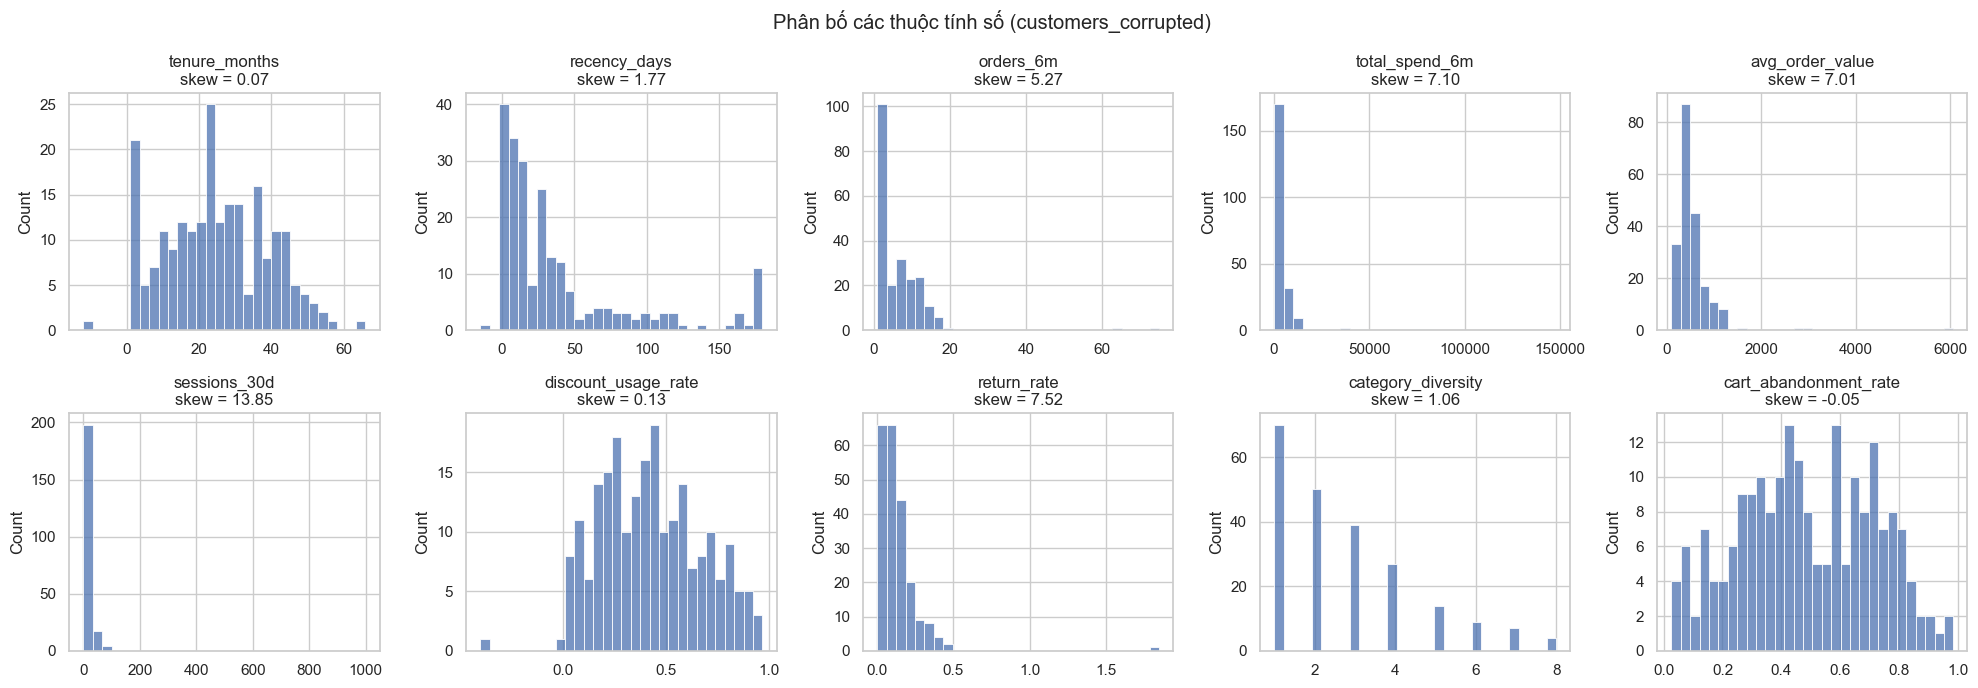

In [26]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, column in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(eda_df[column].dropna(), bins=30, ax=ax)
    ax.set_title(f"{column}\nskew = {eda_df[column].skew():.2f}")
    ax.set_xlabel("")
fig.suptitle("Phân bố các thuộc tính số (customers_corrupted)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_histograms_corrupted.png", dpi=150)
plt.show()

Các giá trị cực lớn làm histogram của `total_spend_6m` và `sessions_30d` bị nén về một cột. Để xem hình dạng phân bố của phần dữ liệu còn lại, vẽ thêm hai biến này trên thang log, chỉ dùng các giá trị không âm.

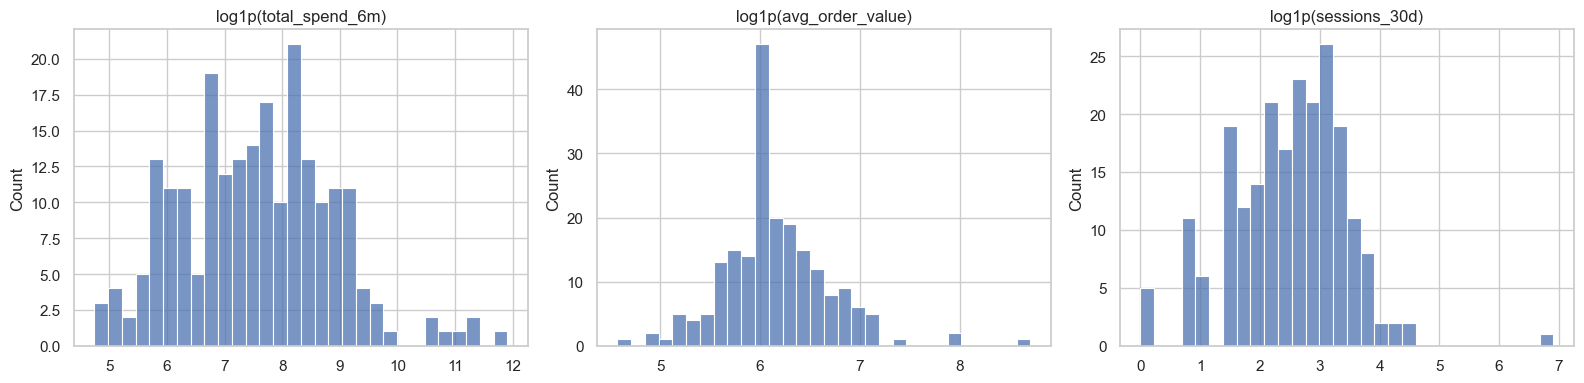

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ["total_spend_6m", "avg_order_value", "sessions_30d"]):
    values = eda_df[column].dropna()
    sns.histplot(np.log1p(values[values >= 0]), bins=30, ax=ax)
    ax.set_title(f"log1p({column})")
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_log_histograms_corrupted.png", dpi=150)
plt.show()

**Nhận xét.**

- **Histogram gốc.**
  - `total_spend_6m`, `sessions_30d`, `avg_order_value` và `return_rate` bị một vài giá trị cực lớn kéo dài trục, nên phần lớn dữ liệu dồn vào vài cột đầu.
  - `recency_days` lệch phải, có một đỉnh nhỏ ở 180 ngày. Đây là giới hạn của cửa sổ quan sát 6 tháng chứ không phải lỗi.
  - `discount_usage_rate` và `cart_abandonment_rate` phân bố tương đối đối xứng.
  - `category_diversity` là biến rời rạc, lệch phải.
- **Sau biến đổi log1p.** `total_spend_6m` và `avg_order_value` có dạng gần đối xứng, với một ít điểm tách ra ở đuôi phải. `sessions_30d` vẫn còn một điểm cô lập ở khoảng 6.9 (log1p của 999). Như vậy, biến đổi log làm giảm độ lệch của phần lớn dữ liệu, nhưng không xử lý được giá trị lỗi.

Boxplot sau khi chuẩn hóa bằng **robust z-score**: (x − median) / IQR. Cách này đưa các biến về cùng đơn vị để so sánh mức độ ngoại lai giữa các biến. Median và IQR cũng không bị chính các ngoại lai làm lệch, khác với mean và std.

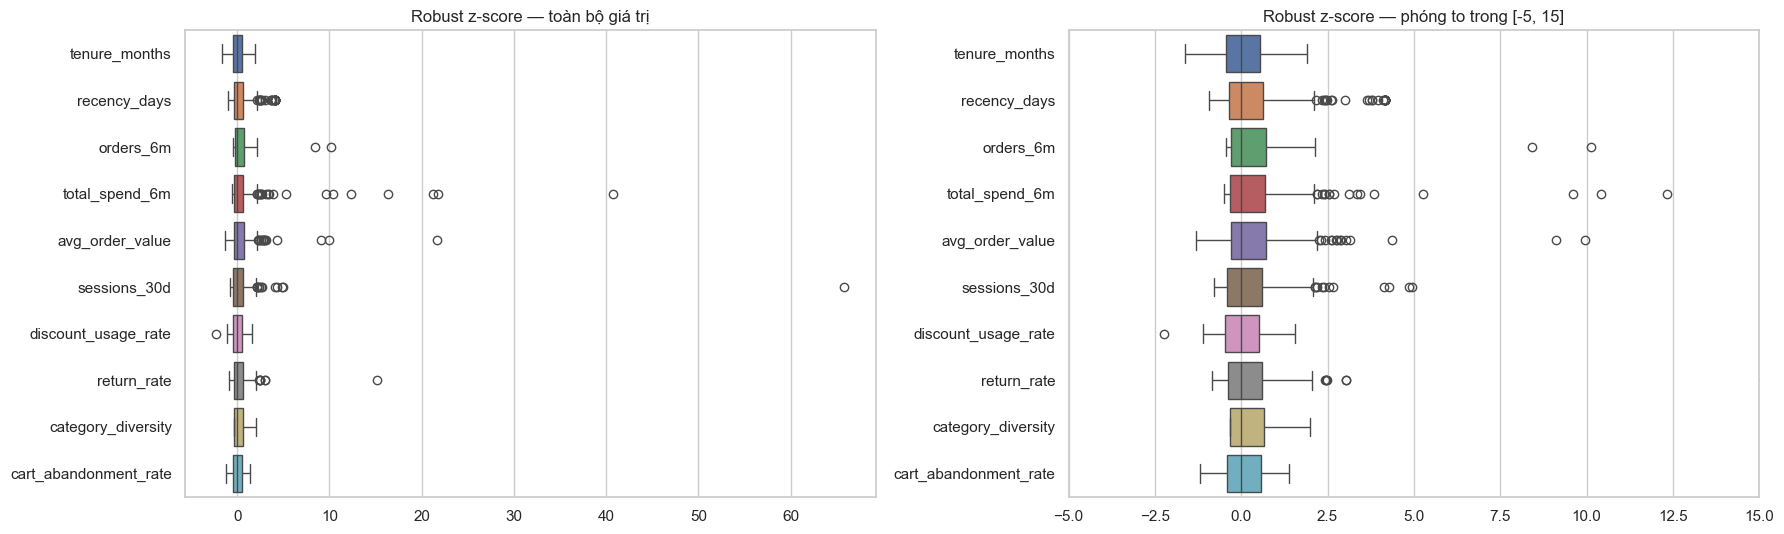

Max robust z-score per feature:
sessions_30d             65.8
total_spend_6m           40.8
avg_order_value          21.6
return_rate              15.2
orders_6m                10.1
recency_days              4.2
discount_usage_rate       2.2
category_diversity        2.0
tenure_months             1.9
cart_abandonment_rate     1.4


In [28]:
def robust_zscore(df):
    iqr = df.quantile(0.75) - df.quantile(0.25)
    return (df - df.median()) / iqr


robust_scaled = robust_zscore(eda_df[NUMERIC_FEATURES])
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, (title, limit) in zip(axes, [("toàn bộ giá trị", None), ("phóng to trong [-5, 15]", (-5, 15))]):
    sns.boxplot(data=robust_scaled, orient="h", ax=ax)
    ax.set_title(f"Robust z-score — {title}")
    if limit:
        ax.set_xlim(limit)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_boxplot_robust_scaled.png", dpi=150)
plt.show()

print("Max robust z-score per feature:")
print(robust_scaled.abs().max().sort_values(ascending=False).round(1).to_string())

**Nhận xét.** Tính theo đơn vị IQR, điểm xa nhất của `sessions_30d` cách trung vị 65.8 IQR, `total_spend_6m` 40.8, `avg_order_value` 21.6, `return_rate` 15.2 và `orders_6m` 10.1. Các điểm này cách biệt hẳn với phần còn lại.

`recency_days` có nhiều điểm vượt râu trên nhưng chỉ tới 4.2 IQR. Phân bố của chúng liên tục chứ không tách thành điểm cô lập, phù hợp với đuôi tự nhiên của một biến lệch phải.

`tenure_months`, `category_diversity` và `cart_abandonment_rate` gần như không có điểm vượt râu. Giá trị âm của `tenure_months` (−12) nằm trong râu dưới, nên boxplot không làm nổi bật được nó.

### b.6. Tương quan giữa các thuộc tính số

So sánh hệ số Pearson (nhạy với ngoại lai, đo quan hệ tuyến tính) với Spearman (dựa trên thứ hạng, bền với ngoại lai). Nếu hai hệ số khác biệt lớn ở cùng một cặp biến, quan hệ đó đang bị ngoại lai hoặc phân bố lệch chi phối.

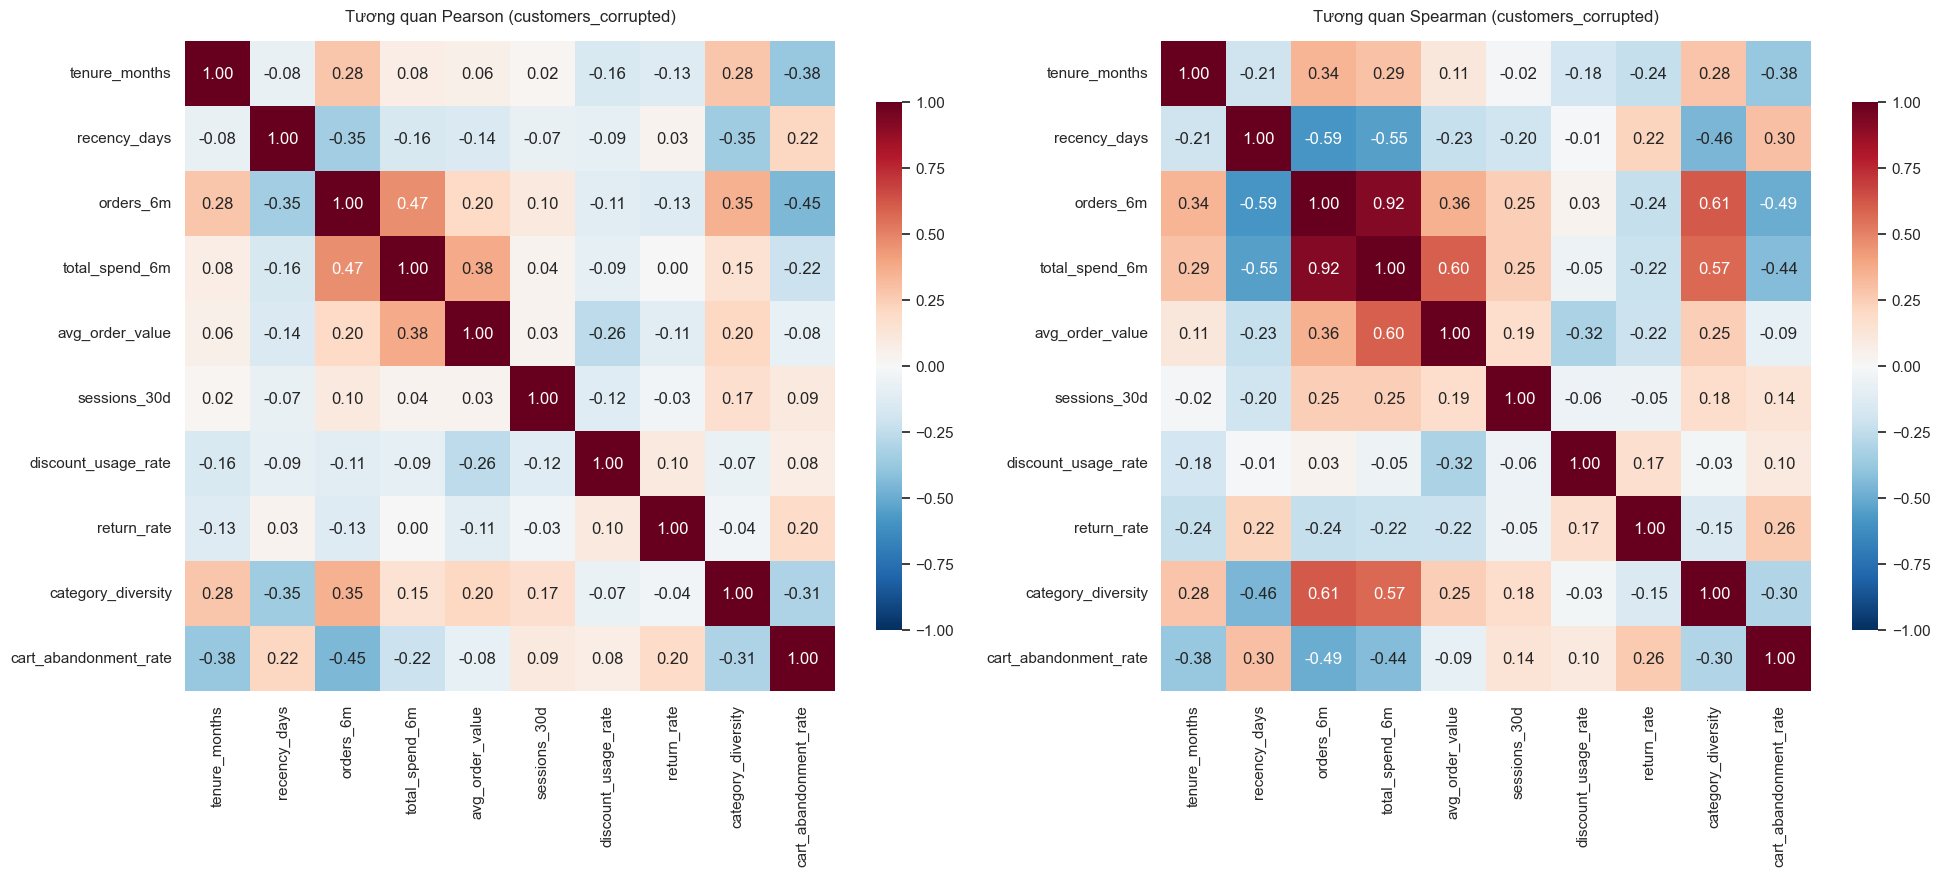

In [29]:
pearson_corr = eda_df[NUMERIC_FEATURES].corr(method="pearson")
spearman_corr = eda_df[NUMERIC_FEATURES].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, (name, corr) in zip(axes, [("Pearson", pearson_corr), ("Spearman", spearman_corr)]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
                cbar_kws={"shrink": 0.7})
    ax.set_title(f"Tương quan {name} (customers_corrupted)", pad=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_correlation_heatmaps.png", dpi=150)
plt.show()

In [30]:
def correlated_pairs(pearson, spearman, threshold=0.5):
    rows = []
    columns = pearson.columns
    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):
            p, s = pearson.iloc[i, j], spearman.iloc[i, j]
            if max(abs(p), abs(s)) >= threshold:
                rows.append({"feature_1": columns[i], "feature_2": columns[j],
                             "pearson": p, "spearman": s, "abs_difference": abs(p - s)})
    return pd.DataFrame(rows).sort_values("spearman", key=abs, ascending=False).reset_index(drop=True)


correlated_pairs(pearson_corr, spearman_corr).round(3)

,feature_1,feature_2,pearson,spearman,abs_difference
0,orders_6m,total_spend_6m,0.465,0.921,0.456
1,orders_6m,category_diversity,0.353,0.614,0.261
2,total_spend_6m,avg_order_value,0.380,0.595,0.216
3,recency_days,orders_6m,-0.349,-0.593,0.244
4,total_spend_6m,category_diversity,0.150,0.572,0.422
5,recency_days,total_spend_6m,-0.164,-0.553,0.389


**Nhận xét.** Theo Spearman, có một nhóm biến cùng phản ánh **mức độ mua hàng**:

- `orders_6m` ~ `total_spend_6m`: 0.92
- `orders_6m` ~ `category_diversity`: 0.61
- `total_spend_6m` ~ `avg_order_value`: 0.60
- `recency_days` ~ `orders_6m`: −0.59
- `total_spend_6m` ~ `category_diversity`: 0.57
- `recency_days` ~ `total_spend_6m`: −0.55

Một phần dư thừa đến từ chính định nghĩa: `total_spend_6m` ≈ `orders_6m` × `avg_order_value`.

Pearson cho cặp `orders_6m` ~ `total_spend_6m` chỉ là 0.47, thấp hơn Spearman 0.46. Lý do là các giá trị cực đoan của `total_spend_6m` (lỗi ×100) không đi kèm số đơn lớn, nên làm yếu quan hệ tuyến tính. Vì vậy, đánh giá dư thừa thông tin nên dựa trên Spearman.

`sessions_30d` chỉ tương quan yếu với `orders_6m` (Spearman 0.25). Truy cập nhiều không đồng nghĩa với mua nhiều, nên biến này mang thông tin riêng.

### b.7. Giá trị không hợp lệ và khả năng phát hiện ngoại lai

**Quy tắc nghiệp vụ.** Các quy tắc được suy ra từ định nghĩa của thuộc tính, không phải từ dữ liệu:

| Quy tắc | Điều kiện vi phạm |
|---|---|
| Biến đếm không âm | `tenure_months`, `recency_days`, `orders_6m`, `sessions_30d` < 0 |
| Tỷ lệ trong [0, 1] | `discount_usage_rate`, `return_rate`, `cart_abandonment_rate` ngoài [0, 1] |
| Tiền tệ không âm | `total_spend_6m`, `avg_order_value` < 0 |
| Phạm vi quan sát | `orders_6m` < 1 hoặc `recency_days` > 180 |
| `category_diversity` | ngoài [1, 8] |
| Recency so với tenure | `recency_days` > 30 × `tenure_months` |
| Số phiên khả thi | `sessions_30d` > 300, tức trung bình hơn 10 phiên/ngày. Đây là ngưỡng do người phân tích đặt cho hành vi người dùng thật |
| Nhất quán chi tiêu | `total_spend_6m` / (`orders_6m` × `avg_order_value`) ngoài [0.5, 2] |

Quy tắc nhất quán chi tiêu cho phép lệch tới 2 lần, vì sai số ghi nhận hợp lý vẫn có thể làm tỷ lệ này khác 1.

In [31]:
RULE_SESSIONS_MAX = 300
RULE_SPEND_RATIO_RANGE = (0.5, 2.0)


def check_business_rules(df):
    # Trả về DataFrame boolean: mỗi cột là một quy tắc, True = bản ghi vi phạm. NaN không bị tính là vi phạm.
    spend_ratio = df["total_spend_6m"] / (df["orders_6m"] * df["avg_order_value"])
    rules = {
        "negative_count": (df[["tenure_months", "recency_days", "orders_6m", "sessions_30d"]] < 0).any(axis=1),
        "rate_out_of_range": ((df[RATE_FEATURES] < 0) | (df[RATE_FEATURES] > 1)).any(axis=1),
        "negative_money": (df[["total_spend_6m", "avg_order_value"]] < 0).any(axis=1),
        "outside_observation_window": (df["orders_6m"] < 1) | (df["recency_days"] > 180),
        "category_diversity_invalid": ~df["category_diversity"].between(1, len(CATEGORIES)),
        "recency_exceeds_tenure": (df["tenure_months"] > 0) & (df["recency_days"] > 30 * df["tenure_months"]),
        "implausible_sessions": df["sessions_30d"] > RULE_SESSIONS_MAX,
        "spend_inconsistent": spend_ratio.notna() & ~spend_ratio.between(*RULE_SPEND_RATIO_RANGE),
    }
    return pd.DataFrame(rules)


rule_violations = check_business_rules(eda_df)
violation_summary = pd.DataFrame({
    "n_records": rule_violations.sum(),
    "customer_ids": [", ".join(eda_df.loc[rule_violations[r], "customer_id"]) for r in rule_violations],
})
print("Records violating at least one rule:", rule_violations.any(axis=1).sum())
violation_summary

Records violating at least one rule: 7


,n_records,customer_ids
negative_count,2,"C0131, C0192"
rate_out_of_range,2,"C0013, C0127"
negative_money,0,
outside_observation_window,0,
category_diversity_invalid,0,
recency_exceeds_tenure,0,
implausible_sessions,1,C0137
spend_inconsistent,2,"C0143, C0146"


**Phát hiện thống kê theo IQR.** Một bản ghi bị đánh dấu nếu ít nhất một thuộc tính số nằm ngoài [Q1 − k·IQR, Q3 + k·IQR]. So sánh hai ngưỡng: k = 1.5 (thông dụng) và k = 3 (chỉ bắt giá trị cực đoan).

In [32]:
def iqr_outlier_flags(df, k):
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    return (df < q1 - k * iqr) | (df > q3 + k * iqr)


iqr_flags = {k: iqr_outlier_flags(eda_df[NUMERIC_FEATURES], k) for k in [1.5, 3.0]}
iqr_counts = pd.DataFrame({f"k={k}": flags.sum() for k, flags in iqr_flags.items()})
iqr_counts.loc["ANY FEATURE (records)"] = [flags.any(axis=1).sum() for flags in iqr_flags.values()]
iqr_counts

,k=1.5,k=3.0
tenure_months,0,0
recency_days,25,15
orders_6m,2,2
total_spend_6m,20,9
avg_order_value,15,4
sessions_30d,12,5
discount_usage_rate,1,0
return_rate,7,1
category_diversity,0,0
cart_abandonment_rate,0,0


**Đối chiếu với metadata (chỉ để đánh giá giả lập).** Phần này so sánh các bản ghi bị đánh dấu với 12 `customer_id` đã chủ động tạo ngoại lai. Kết quả cho biết mỗi phương pháp bắt được bao nhiêu ngoại lai thật và đánh dấu nhầm bao nhiêu bản ghi bình thường. Metadata không được dùng để chọn phương pháp xử lý ở câu c.

In [33]:
detection_methods = {
    "business_rules": rule_violations.any(axis=1),
    "iqr_k1.5": iqr_flags[1.5].any(axis=1),
    "iqr_k3.0": iqr_flags[3.0].any(axis=1),
    "rules_or_iqr_k3.0": rule_violations.any(axis=1) | iqr_flags[3.0].any(axis=1),
}
eval_meta = simulation_metadata.set_index("customer_id").loc[eda_df["customer_id"]]
injected = eval_meta["is_outlier"].to_numpy()

detection_rows = []
for name, flagged in detection_methods.items():
    flagged = flagged.to_numpy()
    detection_rows.append({
        "method": name,
        "flagged_records": flagged.sum(),
        "detected_business_valid": (flagged & (eval_meta["outlier_type"] == "business_valid").to_numpy()).sum(),
        "detected_data_error": (flagged & (eval_meta["outlier_type"] == "data_error").to_numpy()).sum(),
        "detected_total_of_12": (flagged & injected).sum(),
        "flagged_not_injected": (flagged & ~injected).sum(),
    })
detection_summary = pd.DataFrame(detection_rows)
detection_summary

,method,flagged_records,detected_business_valid,detected_data_error,detected_total_of_12,flagged_not_injected
0,business_rules,7,0,7,7,0
1,iqr_k1.5,66,5,5,10,56
2,iqr_k3.0,28,5,4,9,19
3,rules_or_iqr_k3.0,31,5,7,12,19


In [34]:
per_outlier_detection = eval_meta.loc[eval_meta["is_outlier"], ["outlier_type", "outlier_rule"]].copy()
for name, flagged in detection_methods.items():
    per_outlier_detection[name] = flagged.set_axis(eda_df["customer_id"]).loc[per_outlier_detection.index]
per_outlier_detection["violated_rules"] = [
    ", ".join(rule_violations.columns[rule_violations.set_axis(eda_df["customer_id"]).loc[cid]]) or "-"
    for cid in per_outlier_detection.index
]
per_outlier_detection

,outlier_type,outlier_rule,business_rules,iqr_k1.5,iqr_k3.0,rules_or_iqr_k3.0,violated_rules
customer_id,,,,,,,
C0013,data_error,discount_rate_negative,True,True,False,True,rate_out_of_range
C0077,business_valid,very_high_frequency,False,True,True,True,-
C0118,business_valid,vip_high_order_value,False,True,True,True,-
C0127,data_error,return_rate_above_1,True,True,True,True,rate_out_of_range
C0129,business_valid,vip_high_order_value,False,True,True,True,-
C0131,data_error,recency_negative,True,False,False,True,negative_count
C0133,business_valid,very_high_frequency,False,True,True,True,-
C0137,data_error,sessions_tracking_999,True,True,True,True,implausible_sessions
C0143,data_error,spend_unit_x100,True,True,True,True,spend_inconsistent


**Nhận xét.**

- **Quy tắc nghiệp vụ:** đánh dấu 7 bản ghi, đúng là 7 ngoại lai lỗi, không đánh dấu nhầm bản ghi nào. Quy tắc không bắt được 5 ngoại lai nghiệp vụ, điều này hợp lý vì chúng không vi phạm ràng buộc nào.
- **IQR k = 1.5:** đánh dấu 66 bản ghi (30% dữ liệu), bắt được 10/12 ngoại lai, nhưng có 56 bản ghi không được can thiệp, chủ yếu do đuôi tự nhiên của `recency_days` (25) và `total_spend_6m` (20). IQR bỏ sót C0131 (`recency_days` = −15) và C0192 (`tenure_months` = −12), vì các giá trị âm nhỏ này vẫn nằm trong râu dưới.
- **IQR k = 3:** đánh dấu 28 bản ghi, bắt được 9/12, có 19 bản ghi bình thường bị đánh dấu.
- **Kết hợp quy tắc nghiệp vụ với IQR k = 3:** bắt đủ 12/12, kèm 19 bản ghi bình thường bị đánh dấu.

Không có phương pháp đơn lẻ nào vừa bắt đủ vừa không đánh dấu nhầm. Quy tắc nghiệp vụ chính xác cho lỗi vi phạm miền giá trị. IQR cần cho giá trị cực lớn nhưng hợp lệ về miền, đồng thời dễ đánh dấu nhầm đuôi tự nhiên của biến lệch. Bản ghi bị IQR đánh dấu vì vậy không nên bị xóa tự động.

### b.8. So sánh dữ liệu trước và sau khi đưa vào lỗi

Bảng dưới so sánh thống kê của `customers_original` và `customers_corrupted`. Mục đích là định lượng tác động của nhiễu, ngoại lai và giá trị thiếu lên các thống kê mà K-Means và bước chuẩn hóa sử dụng (mean, std), cũng như các thống kê bền vững hơn (median, IQR).

In [35]:
reference_df = pd.read_csv(DATA_DIR / "customers_original.csv")


def compare_statistics(before, after, columns):
    rows = []
    for column in columns:
        b, a = before[column], after[column].dropna()
        rows.append({
            "feature": column,
            "mean_before": b.mean(), "mean_after": a.mean(),
            "median_before": b.median(), "median_after": a.median(),
            "std_before": b.std(), "std_after": a.std(),
            "max_before": b.max(), "max_after": a.max(),
            "skew_before": b.skew(), "skew_after": a.skew(),
        })
    table = pd.DataFrame(rows).set_index("feature")
    table["std_ratio"] = table["std_after"] / table["std_before"]
    return table


before_after_stats = compare_statistics(reference_df, eda_df, NUMERIC_FEATURES)
before_after_stats.round(3)

,mean_before,mean_after,median_before,median_after,std_before,std_after,max_before,max_after,skew_before,skew_after,std_ratio
feature,,,,,,,,,,,
tenure_months,24.755,24.568,24.000,24.000,14.203,14.414,66.000,66.000,0.114,0.072,1.015
recency_days,39.164,39.014,21.000,21.000,48.215,48.339,180.000,180.000,1.782,1.771,1.003
orders_6m,5.850,6.359,4.000,4.000,4.767,7.664,19.000,75.000,0.774,5.273,1.608
total_spend_6m,3287.774,5216.698,1935.900,1938.810,3610.793,13766.111,18834.700,147995.000,1.845,7.099,3.812
avg_order_value,512.623,556.216,437.365,435.650,260.905,517.121,1789.310,6064.050,1.600,7.008,1.982
sessions_30d,14.945,20.118,12.000,12.000,12.875,67.841,86.000,999.000,1.799,13.854,5.269
discount_usage_rate,0.432,0.427,0.414,0.408,0.240,0.246,0.970,0.970,0.270,0.128,1.024
return_rate,0.125,0.131,0.100,0.100,0.093,0.147,0.452,1.850,1.255,7.516,1.588
category_diversity,2.727,2.727,2.000,2.000,1.775,1.775,8.000,8.000,1.063,1.063,1.000


In [36]:
corr_pairs_to_track = [("orders_6m", "total_spend_6m"), ("avg_order_value", "total_spend_6m"),
                       ("orders_6m", "recency_days"), ("sessions_30d", "orders_6m"),
                       ("orders_6m", "category_diversity")]
original_pearson = reference_df[NUMERIC_FEATURES].corr()
original_spearman = reference_df[NUMERIC_FEATURES].corr(method="spearman")
pd.DataFrame([{
    "pair": f"{x} ~ {y}",
    "pearson_original": original_pearson.loc[x, y], "pearson_corrupted": pearson_corr.loc[x, y],
    "spearman_original": original_spearman.loc[x, y], "spearman_corrupted": spearman_corr.loc[x, y],
} for x, y in corr_pairs_to_track]).round(3)

,pair,pearson_original,pearson_corrupted,spearman_original,spearman_corrupted
0,orders_6m ~ total_spend_6m,0.847,0.465,0.938,0.921
1,avg_order_value ~ total_spend_6m,0.587,0.380,0.600,0.595
2,orders_6m ~ recency_days,-0.474,-0.349,-0.583,-0.593
3,sessions_30d ~ orders_6m,0.070,0.099,0.284,0.248
4,orders_6m ~ category_diversity,0.578,0.353,0.617,0.614


**Nhận xét.**

- **Độ lệch chuẩn tăng mạnh.** So với dữ liệu sạch, std tăng 5.27 lần ở `sessions_30d`, 3.81 lần ở `total_spend_6m`, 1.98 lần ở `avg_order_value`, 1.61 lần ở `orders_6m` và 1.59 lần ở `return_rate`.
- **Trung bình bị kéo lên, trung vị gần như không đổi.** Trung bình `total_spend_6m` tăng từ 3287.8 lên 5216.7, trong khi trung vị chỉ đổi từ 1935.9 sang 1938.8. Skewness của `sessions_30d` tăng từ 1.80 lên 13.85.
- **Các biến không bị can thiệp giữ nguyên**, ví dụ `category_diversity`.
- **Pearson bị ảnh hưởng, Spearman thì không.** Pearson giữa `orders_6m` và `total_spend_6m` giảm từ 0.847 xuống 0.465, còn Spearman gần như không đổi (0.938 sang 0.921).

Như vậy, nhiễu và ngoại lai tác động chủ yếu lên các thống kê dựa trên trung bình và bình phương độ lệch (mean, std, Pearson), là các đại lượng mà chuẩn hóa z-score và K-Means sử dụng trực tiếp.

### b.9. Các vấn đề dữ liệu ảnh hưởng đến phân cụm

**Vấn đề 1 — Phân bố lệch và chênh lệch thang đo.**

*Bằng chứng (b.2, b.5):* độ lệch chuẩn giữa các biến chênh nhau khoảng 10⁵ lần. Năm biến có skewness từ 5 đến 14, và phân bố của `total_spend_6m`, `avg_order_value` sau log1p gần đối xứng hơn.

*Ảnh hưởng đến K-Means:* K-Means dùng khoảng cách Euclid.
- Nếu không đưa về cùng thang đo, `total_spend_6m` gần như quyết định toàn bộ khoảng cách, còn các tỷ lệ trong [0, 1] không còn vai trò.
- Với biến lệch phải, các điểm ở đuôi dài nằm xa trung tâm và góp phần lớn vào tổng bình phương sai số (SSE). Tâm cụm bị kéo về phía đuôi, hoặc thuật toán dành riêng một cụm cho vài điểm đuôi. Điều này đi ngược giả định của K-Means là các cụm có dạng gần cầu và kích thước tương đương.

**Vấn đề 2 — Tương quan và thông tin dư thừa.**

*Bằng chứng (b.6):* `orders_6m`, `total_spend_6m`, `avg_order_value`, `category_diversity` và `recency_days` tương quan Spearman với nhau ở mức |0.55–0.92|. `total_spend_6m` gần như được xác định bởi `orders_6m` × `avg_order_value`.

*Ảnh hưởng đến K-Means:* khoảng cách Euclid coi mỗi chiều là độc lập. Khi nhiều biến cùng đo "mức độ mua hàng", chiều này được tính nhiều lần và lấn át các khía cạnh hành vi khác như mức dùng giảm giá, tỷ lệ bỏ giỏ hay số phiên truy cập. Hệ quả là các cụm có xu hướng chỉ phân tầng theo mức chi tiêu, khó tách được nhóm săn khuyến mãi hay nhóm chỉ xem hàng.

**Vấn đề 3 — Giá trị thiếu.**

*Bằng chứng (b.4):* 31 bản ghi (14.1%) có giá trị thiếu. Giá trị thiếu của `cart_abandonment_rate` tập trung ở khách có ít phiên và ít đơn.

*Ảnh hưởng đến K-Means:* `KMeans` của scikit-learn không nhận NaN.
- Xóa bản ghi thiếu làm mất 14.1% mẫu và làm lệch tập dữ liệu, vì loại bỏ nhiều khách ít hoạt động hơn, tức đúng nhóm cần nhận diện.
- Điền bằng một giá trị toàn cục (trung vị hoặc trung bình) đặt các bản ghi này vào vị trí trung tâm của biến đó, có thể kéo chúng sai cụm. Điều này đặc biệt đáng lo khi giá trị thiếu phụ thuộc vào mức hoạt động.

**Vấn đề 4 — Ngoại lai và nhiễu.**

*Bằng chứng (b.5, b.7, b.8):*
- Có các điểm cách trung vị tới 65.8 IQR (`sessions_30d` = 999) và 40.8 IQR (`total_spend_6m`).
- 7 bản ghi vi phạm quy tắc nghiệp vụ. 5 bản ghi có chi tiêu hoặc tần suất rất cao nhưng hợp lệ.
- Std của `sessions_30d` và `total_spend_6m` tăng 5.27 và 3.81 lần so với dữ liệu sạch.

*Ảnh hưởng đến K-Means:*
- K-Means tối thiểu hóa tổng bình phương khoảng cách, nên một điểm cực đoan có thể chiếm trọn một cụm hoặc kéo lệch tâm cụm.
- Ngoại lai cũng làm std bị thổi phồng. Khi chuẩn hóa z-score, std lớn nén sự khác biệt giữa các khách hàng bình thường lại, làm giảm khả năng phân tách.
- Nhiễu (khoảng 10% với chi tiêu; với số phiên, thay đổi tương đối trung bình 35% trên các bản ghi bị tác động) làm mờ ranh giới giữa các cụm vốn đã chồng lấn. Nhiễu cũng khó loại bỏ ở mức từng bản ghi vì không tạo giá trị bất thường rõ ràng.
- Hai loại ngoại lai cần xử lý khác nhau. Lỗi dữ liệu nên được coi là giá trị sai. Ngoại lai nghiệp vụ là khách hàng thật, không nên xóa, nhưng cần giảm ảnh hưởng của chúng lên khoảng cách.